# CRM Dashboard, Olist Brazilian E-Commerce

Notebook ini menyiapkan data untuk dashboard CRM. Alurnya satu arah, dari CSV mentah sampai tabel siap saji. Semua hasil akhir ditulis ke `olist.duckdb` di schema `marts`, dan nanti hanya schema itu yang dibaca Streamlit.

Urutan kerja:

1. inventaris dan integritas data
2. definisi universe order yang dipakai
3. `fct_orders`, satu baris per order
4. baseline KPI dan agregat bulanan serta state
5. agregasi pelanggan
6. RFM dan segmen
7. churn dan cohort retensi
8. analisis loyalitas
9. geografi
10. afinitas segmen dan kategori
11. kontrak mart
12. rekonsiliasi

Angka di notebook ini yang jadi sumber kebenaran. Kalau nanti ada yang berbeda di dashboard, yang benar adalah notebook ini.

## 0. Setup

Semua query memakai DuckDB langsung dari file CSV, tanpa load ke memori lebih dulu. Koneksi ditulis ke satu file database supaya bisa dibaca app lain.

In [1]:
from pathlib import Path
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
pd.set_option("display.max_rows", 100)

ROOT = Path.cwd()
while not (ROOT / "data" / "raw" / "olist").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

RAW = ROOT / "data" / "raw" / "olist"
FIG = ROOT / "figures"
DB = ROOT / "olist.duckdb"
FIG.mkdir(exist_ok=True)

con = duckdb.connect(DB)
print("database siap:", DB.name)

def q(sql):
    return con.sql(sql).df()

database siap: olist.duckdb


Tabel CSV didaftarkan sebagai view, jadi belum ada data yang disalin. Penamaan `raw_` supaya jelas mana yang mentah dan mana yang sudah diolah.

In [2]:
FILES = {
    "orders": "olist_orders_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "payments": "olist_order_payments_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "customers": "olist_customers_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
    "category": "product_category_name_translation.csv",
}

# file reviews punya beberapa baris dengan kutip tidak seimbang di kolom komentar,
# jadi parsing dibuat longgar dan baris rusak dilewati
READ_OPTS = {
    "reviews": """, delim=',', quote='"', escape='"', strict_mode=false, ignore_errors=true""",
}

for name, fname in FILES.items():
    extra = READ_OPTS.get(name, "")
    con.execute(
        f"CREATE OR REPLACE VIEW raw_{name} AS "
        f"SELECT * FROM read_csv_auto('{RAW / fname}', header=true{extra})"
    )

q("SELECT table_name, table_type FROM information_schema.tables WHERE table_schema = 'main' ORDER BY 1")

,table_name,table_type
0,raw_category,VIEW
1,raw_customers,VIEW
2,raw_geolocation,VIEW
3,raw_order_items,VIEW
4,raw_orders,VIEW
5,raw_payments,VIEW
6,raw_products,VIEW
7,raw_reviews,VIEW
8,raw_sellers,VIEW


Catatan kecil soal kualitas data. File review berisi sekitar 99.2 ribu baris, dan 10 di antaranya rusak karena tanda kutip tidak seimbang di kolom komentar. Baris itu dilewati. Dampaknya tidak berarti untuk skor rating, tapi tetap perlu disebut di laporan sebagai bagian dari pembersihan data.

## 1. Inventaris data

Sebelum menghitung apa pun, pastikan bentuk tiap tabel sesuai dugaan. Yang dicari di bagian ini ada tiga. Jumlah baris, tipe kolom, dan apakah kolom kunci benar-benar unik.

In [3]:
rows = []
for name in FILES:
    n = int(con.execute(f"SELECT count(*) AS n FROM raw_{name}").df()["n"].iloc[0])
    cols = con.sql(f"DESCRIBE raw_{name}").df()
    rows.append({"tabel": f"raw_{name}", "baris": n, "kolom": len(cols)})

inv = pd.DataFrame(rows).sort_values("baris", ascending=False)
inv

,tabel,baris,kolom
7,raw_geolocation,1000163,5
1,raw_order_items,112650,7
2,raw_payments,103886,5
0,raw_orders,99441,8
4,raw_customers,99441,5
3,raw_reviews,99214,7
5,raw_products,32951,9
6,raw_sellers,3095,4
8,raw_category,73,2


Tiga tabel yang paling menentukan. `raw_customers` punya dua identitas, `customer_id` dan `customer_unique_id`. `raw_payments` dan `raw_order_items` bisa lebih dari satu baris per order. Dua fakta ini yang menentukan cara join nanti.

In [4]:
q("""
SELECT
    (SELECT count(*) FROM raw_orders)                              AS baris_order,
    (SELECT count(DISTINCT order_id) FROM raw_orders)              AS order_id_unik,
    (SELECT count(*) FROM raw_customers)                           AS baris_customer,
    (SELECT count(DISTINCT customer_id) FROM raw_customers)        AS customer_id_unik,
    (SELECT count(DISTINCT customer_unique_id) FROM raw_customers) AS customer_unik,
    (SELECT count(DISTINCT order_id) FROM raw_payments)            AS order_punya_payment,
    (SELECT count(DISTINCT order_id) FROM raw_reviews)             AS order_punya_review
""")

,baris_order,order_id_unik,baris_customer,customer_id_unik,customer_unik,order_punya_payment,order_punya_review
0,99441,99441,99441,99441,96096,99440,98663


Kalau `customer_id` unik sama dengan jumlah baris, berarti satu baris per order. Itu artinya memakai `customer_id` untuk menghitung pelanggan akan salah. Harus `customer_unique_id`.

Berikutnya distribusi jumlah baris payment dan item per order. Inilah sumber penggelembungan angka kalau join dilakukan langsung dari order ke payment lalu ke item.

In [5]:
display(q("""
WITH p AS (SELECT order_id, count(*) AS n FROM raw_payments GROUP BY 1)
SELECT n AS baris_payment_per_order, count(*) AS jumlah_order
FROM p GROUP BY 1 ORDER BY 1
"""))

display(q("""
WITH i AS (SELECT order_id, count(*) AS n FROM raw_order_items GROUP BY 1)
SELECT n AS baris_item_per_order, count(*) AS jumlah_order
FROM i GROUP BY 1 ORDER BY 1
"""))

,baris_payment_per_order,jumlah_order
0,1,96479
1,2,2382
2,3,301
3,4,108
4,5,52
5,6,36
6,7,28
7,8,11
8,9,9
9,10,5


,baris_item_per_order,jumlah_order
0,1,88863
1,2,7516
2,3,1322
3,4,505
4,5,204
5,6,198
6,7,22
7,8,8
8,9,3
9,10,8


Rentang tanggal dan status order menentukan jendela analisis. Perhatikan bahwa sebagian order tahun 2016 sangat sedikit, dan data berakhir di 2018. Semua perhitungan recency nanti harus memakai tanggal maksimum data, bukan tanggal hari ini.

In [6]:
q("""
SELECT
    order_status,
    count(*)                          AS orders,
    min(CAST(order_purchase_timestamp AS TIMESTAMP)) AS order_pertama,
    max(CAST(order_purchase_timestamp AS TIMESTAMP)) AS order_terakhir
FROM raw_orders
GROUP BY 1
ORDER BY 2 DESC
""")

,order_status,orders,order_pertama,order_terakhir
0,delivered,96478,2016-09-15 12:16:38,2018-08-29 15:00:37
1,shipped,1107,2016-09-04 21:15:19,2018-09-03 09:06:57
2,canceled,625,2016-09-05 00:15:34,2018-10-17 17:30:18
3,unavailable,609,2016-10-05 14:16:28,2018-08-21 12:21:00
4,invoiced,314,2016-10-04 13:02:10,2018-08-14 18:45:08
5,processing,301,2016-10-05 22:44:13,2018-07-23 18:03:03
6,created,5,2017-11-06 13:12:34,2018-02-09 17:21:04
7,approved,2,2017-02-06 20:18:17,2017-04-25 01:25:34


In [7]:
q("""
SELECT
    count(*) FILTER (WHERE order_approved_at IS NULL)            AS approved_null,
    count(*) FILTER (WHERE order_delivered_carrier_date IS NULL) AS carrier_null,
    count(*) FILTER (WHERE order_delivered_customer_date IS NULL) AS delivered_null,
    count(*) FILTER (WHERE order_estimated_delivery_date IS NULL) AS estimasi_null
FROM raw_orders
""")

,approved_null,carrier_null,delivered_null,estimasi_null
0,160,1783,2965,0


## 2. Definisi universe order

Bagian ini adalah keputusan, bukan eksplorasi. Aturan yang dipakai:

- status `canceled` dan `unavailable` dibuang, karena tidak menghasilkan pendapatan
- jendela analisis 1 Januari 2017 sampai 31 Agustus 2018, karena 2016 terlalu tipis dan datanya berhenti di 2018
- GMV memakai `payment_value` (uang yang benar-benar dibayar), sementara nilai barang dan ongkir disimpan terpisah di kolom sendiri
- pelanggan dihitung dengan `customer_unique_id`, bukan `customer_id`

Konsekuensi dari aturan ini ditampilkan di sel berikut, supaya jelas berapa data yang dibuang.

In [8]:
q("""
WITH dipakai AS (
    SELECT *
    FROM raw_orders
    WHERE order_status NOT IN ('canceled', 'unavailable')
      AND CAST(order_purchase_timestamp AS TIMESTAMP) >= TIMESTAMP '2017-01-01'
      AND CAST(order_purchase_timestamp AS TIMESTAMP) <  TIMESTAMP '2018-09-01'
)
SELECT
    (SELECT count(*) FROM raw_orders) AS semua_order,
    (SELECT count(*) FROM dipakai)    AS order_dipakai,
    (SELECT count(*) FROM raw_orders
      WHERE order_status IN ('canceled', 'unavailable')) AS dibuang_status,
    (SELECT count(*) FROM raw_orders
      WHERE CAST(order_purchase_timestamp AS TIMESTAMP) < TIMESTAMP '2017-01-01') AS dibuang_tahun_2016,
    (SELECT round(100.0 * count(*) / (SELECT count(*) FROM raw_orders), 2) FROM dipakai) AS pct_dipakai
""")

,semua_order,order_dipakai,dibuang_status,dibuang_tahun_2016,pct_dipakai
0,99441,97910,1234,329,98.46


## 3. `fct_orders`

Satu baris per order, dan semua join berat selesai di sini. Tiga agregasi dilakukan lebih dulu supaya tidak ada duplikasi, yaitu payment per order, item per order, dan kategori dominan per order. Kategori dominan diambil dari nilai barang terbesar, bukan kategori pertama yang muncul.

Kolom yang dihasilkan sudah cukup untuk seluruh halaman dashboard, jadi Streamlit tidak perlu join apa pun.

In [9]:
con.execute("CREATE SCHEMA IF NOT EXISTS marts")

con.execute("""
CREATE OR REPLACE TABLE marts.fct_orders AS
WITH pay AS (
    SELECT
        order_id,
        sum(payment_value)                                  AS payment_total,
        max(payment_installments)                           AS max_installments,
        arg_max(payment_type, payment_value)                AS main_payment_type
    FROM raw_payments
    GROUP BY 1
),
items AS (
    SELECT
        order_id,
        sum(price)                  AS item_total,
        sum(freight_value)          AS freight_total,
        count(*)                    AS n_items,
        count(DISTINCT product_id)  AS n_products,
        count(DISTINCT seller_id)   AS n_sellers
    FROM raw_order_items
    GROUP BY 1
),
kategori AS (
    SELECT
        oi.order_id,
        arg_max(coalesce(t.product_category_name_english, p.product_category_name), oi.price) AS category
    FROM raw_order_items oi
    LEFT JOIN raw_products p ON p.product_id = oi.product_id
    LEFT JOIN raw_category t ON t.product_category_name = p.product_category_name
    GROUP BY 1
),
review AS (
    SELECT order_id, avg(review_score) AS review_score
    FROM raw_reviews
    GROUP BY 1
)
SELECT
    o.order_id,
    c.customer_unique_id,
    o.order_status,
    CAST(o.order_purchase_timestamp AS TIMESTAMP)                    AS purchased_at,
    CAST(o.order_purchase_timestamp AS DATE)                         AS order_date,
    date_trunc('month', CAST(o.order_purchase_timestamp AS TIMESTAMP))::DATE AS order_month,
    c.customer_state,
    c.customer_city,
    coalesce(pay.payment_total, 0)      AS payment_total,
    coalesce(items.item_total, 0)       AS item_total,
    coalesce(items.freight_total, 0)    AS freight_total,
    coalesce(items.n_items, 0)          AS n_items,
    items.n_products,
    items.n_sellers,
    pay.main_payment_type,
    pay.max_installments,
    kategori.category,
    review.review_score,
    date_diff(
        'day',
        CAST(o.order_purchase_timestamp AS TIMESTAMP),
        CAST(o.order_delivered_customer_date AS TIMESTAMP)
    ) AS delivery_days,
    CASE
        WHEN o.order_delivered_customer_date IS NULL THEN NULL
        WHEN CAST(o.order_delivered_customer_date AS TIMESTAMP)
           > CAST(o.order_estimated_delivery_date AS TIMESTAMP) THEN 1
        ELSE 0
    END AS late_flag
FROM raw_orders o
JOIN raw_customers c ON c.customer_id = o.customer_id
LEFT JOIN pay       ON pay.order_id = o.order_id
LEFT JOIN items     ON items.order_id = o.order_id
LEFT JOIN kategori  ON kategori.order_id = o.order_id
LEFT JOIN review    ON review.order_id = o.order_id
WHERE o.order_status NOT IN ('canceled', 'unavailable')
  AND CAST(o.order_purchase_timestamp AS TIMESTAMP) >= TIMESTAMP '2017-01-01'
  AND CAST(o.order_purchase_timestamp AS TIMESTAMP) <  TIMESTAMP '2018-09-01'
""")

q("SELECT count(*) AS orders, count(DISTINCT customer_unique_id) AS customers FROM marts.fct_orders")

,orders,customers
0,97910,94707


In [10]:
q("SELECT * FROM marts.fct_orders ORDER BY purchased_at LIMIT 5")

,order_id,customer_unique_id,order_status,purchased_at,order_date,order_month,customer_state,customer_city,payment_total,item_total,freight_total,n_items,n_products,n_sellers,main_payment_type,max_installments,category,review_score,delivery_days,late_flag
0,ec7a019261fce44180373d45b442d78f,f7b981e8a280e455ac3cbe0d5d171bd1,delivered,2017-01-05 11:56:06,2017-01-05,2017-01-01,PR,curitiba,19.62,10.9,8.72,1,1,1,credit_card,1,fashion_bags_accessories,5.0,6,0
1,b95a0a8bd30aece4e94e81f0591249d8,83e7958a94bd7f74a9414d8782f87628,delivered,2017-01-05 12:01:20,2017-01-05,2017-01-01,PR,curitiba,19.62,10.9,8.72,1,1,1,boleto,1,auto,5.0,12,0
2,38bcb524e1c38c2c1b60600a80fc8999,728e4a7d0db4845270091ded0923c71f,delivered,2017-01-05 12:06:36,2017-01-05,2017-01-01,PR,curitiba,11.62,2.9,8.72,1,1,1,boleto,1,pet_shop,5.0,11,0
3,7a18a504c1a4b32d883e68de2e1a7db0,728e4a7d0db4845270091ded0923c71f,delivered,2017-01-05 12:09:08,2017-01-05,2017-01-01,PR,curitiba,16.62,7.9,8.72,1,1,1,boleto,1,pet_shop,5.0,11,0
4,6acecf438369055d9243e121045cca74,728e4a7d0db4845270091ded0923c71f,delivered,2017-01-05 12:11:23,2017-01-05,2017-01-01,PR,curitiba,18.62,9.9,8.72,1,1,1,boleto,1,pet_shop,5.0,12,0


## 4. Baseline KPI

Ini yang muncul di halaman pertama dashboard. Perhatikan `repeat_rate`. Angkanya akan kecil, dan itu bukan kesalahan hitung. Olist memang didominasi pembeli sekali.

In [11]:
q("""
SELECT
    count(*)                                                    AS orders,
    count(DISTINCT customer_unique_id)                           AS customers,
    round(sum(payment_total), 2)                                 AS gmv,
    round(avg(payment_total), 2)                                 AS aov,
    round(sum(payment_total) / count(DISTINCT customer_unique_id), 2) AS gmv_per_customer,
    round(avg(review_score), 2)                                  AS rating,
    round(avg(delivery_days), 1)                                 AS rata_hari_kirim,
    round(avg(late_flag), 3)                                     AS late_rate
FROM marts.fct_orders
""")

,orders,customers,gmv,aov,gmv_per_customer,rating,rata_hari_kirim,late_rate
0,97910,94707,15687157.17,160.22,165.64,4.12,12.5,0.081


In [12]:
q("""
WITH c AS (
    SELECT customer_unique_id, count(*) AS n_orders
    FROM marts.fct_orders
    GROUP BY 1
)
SELECT
    count(*)                                        AS customers,
    count(*) FILTER (WHERE n_orders = 1)            AS sekali_beli,
    count(*) FILTER (WHERE n_orders >= 2)           AS repeat_customer,
    round(100.0 * count(*) FILTER (WHERE n_orders >= 2) / count(*), 2) AS repeat_rate_pct
FROM c
""")

,customers,sekali_beli,repeat_customer,repeat_rate_pct
0,94707,91832,2875,3.04


Agregat bulanan dipakai untuk tren di halaman 1. Grain-nya bulanan, jadi filter tanggal di dashboard tetap perlu tabel fakta, bukan tabel ini.

In [13]:
con.execute("""
CREATE OR REPLACE TABLE marts.agg_monthly AS
SELECT
    order_month,
    count(*)                            AS orders,
    count(DISTINCT customer_unique_id)  AS customers,
    sum(payment_total)                  AS gmv,
    avg(payment_total)                  AS aov,
    avg(review_score)                   AS rating
FROM marts.fct_orders
GROUP BY 1
ORDER BY 1
""")

q("SELECT * FROM marts.agg_monthly")

,order_month,orders,customers,gmv,aov,rating
0,2017-01-01,787,753,137006.76,174.087370,4.093308
1,2017-02-01,1718,1693,283621.94,165.088440,4.101874
2,2017-03-01,2617,2577,425656.40,162.650516,4.132217
3,2017-04-01,2377,2345,405988.38,170.798645,4.069097
4,2017-05-01,3640,3569,582926.16,160.144549,4.178591
5,2017-06-01,3205,3142,499827.47,155.952409,4.177146
6,2017-07-01,3946,3872,578858.58,146.695028,4.225475
7,2017-08-01,4272,4191,662071.77,154.979347,4.267036
8,2017-09-01,4227,4154,717195.22,169.670031,4.221388
9,2017-10-01,4547,4481,764785.28,168.195575,4.174983


Agregat per state menjawab pertanyaan asal pelanggan sekaligus menunjukkan kualitas layanan per wilayah. `late_rate` berguna untuk menjelaskan kenapa pelanggan di suatu wilayah jarang kembali.

In [14]:
con.execute("""
CREATE OR REPLACE TABLE marts.agg_state AS
SELECT
    customer_state                                              AS state,
    count(*)                                                    AS orders,
    count(DISTINCT customer_unique_id)                           AS customers,
    sum(payment_total)                                           AS gmv,
    sum(payment_total) / count(DISTINCT customer_unique_id)      AS gmv_per_customer,
    avg(delivery_days)                                           AS avg_delivery_days,
    avg(late_flag)                                               AS late_rate,
    avg(review_score)                                            AS rating
FROM marts.fct_orders
GROUP BY 1
ORDER BY gmv DESC
""")

q("SELECT * FROM marts.agg_state LIMIT 12")

,state,orders,customers,gmv,gmv_per_customer,avg_delivery_days,late_rate,rating
0,SP,41022,39649,5864107.01,147.900502,8.676626,0.059011,4.212918
1,RJ,12655,12201,2105927.98,172.602900,15.224127,0.135175,3.904859
2,MG,11457,11098,1838009.59,165.616290,11.920311,0.056277,4.166652
3,RS,5396,5213,874070.24,167.671253,15.236531,0.071710,4.156930
4,PR,4963,4806,792053.23,164.805083,11.919029,0.050173,4.212318
5,BA,3340,3240,606046.11,187.051269,19.276975,0.140486,3.883904
6,SC,3590,3493,605603.60,173.376353,14.893978,0.097823,4.099663
7,DF,2115,2052,350287.52,170.705419,12.869817,0.070878,4.092443
8,GO,1990,1927,339471.57,176.165838,15.540513,0.082051,4.067274
9,ES,2014,1946,322038.61,165.487467,15.710341,0.122490,4.055360


## 5. Agregasi pelanggan

Grain pindah ke `customer_unique_id`. Tabel ini jadi bahan RFM, dan sekaligus menjawab pertanyaan berapa nilai transaksi tiap pelanggan.

In [15]:
con.execute("""
CREATE OR REPLACE TABLE marts.int_customer_base AS
SELECT
    customer_unique_id,
    min(order_date)                     AS first_order_date,
    max(order_date)                     AS last_order_date,
    count(*)                            AS n_orders,
    sum(payment_total)                  AS monetary,
    avg(payment_total)                  AS aov,
    sum(n_items)                        AS n_items,
    avg(review_score)                   AS avg_review,
    any_value(customer_state)           AS state,
    any_value(customer_city)            AS city,
    arg_max(category, payment_total)    AS top_category
FROM marts.fct_orders
GROUP BY 1
""")

q("SELECT * FROM marts.int_customer_base ORDER BY monetary DESC LIMIT 5")

,customer_unique_id,first_order_date,last_order_date,n_orders,monetary,aov,n_items,avg_review,state,city,top_category
0,0a0a92112bd4c708ca5fde585afaa872,2017-09-29,2017-09-29,1,13664.08,13664.080,8.0,1.0,RJ,rio de janeiro,fixed_telephony
1,da122df9eeddfedc1dc1f5349a1a690c,2017-04-01,2017-04-01,2,7571.63,3785.815,2.0,5.0,RJ,araruama,small_appliances
2,763c8b1c9c68a0229c42c9fc6f662b93,2018-07-15,2018-07-15,1,7274.88,7274.880,4.0,1.0,ES,vila velha,fixed_telephony
3,dc4802a71eae9be1dd28f5d788ceb526,2017-02-12,2017-02-12,1,6929.31,6929.310,1.0,5.0,MS,campo grande,housewares
4,459bef486812aa25204be022145caa62,2018-07-25,2018-07-25,1,6922.21,6922.210,1.0,NaN,ES,vitoria,computers


In [16]:
q("""
SELECT
    CASE WHEN n_orders >= 5 THEN '5+' ELSE n_orders::VARCHAR END AS bucket,
    count(*)                                                     AS customers,
    round(100.0 * count(*) / sum(count(*)) OVER (), 2)           AS pct
FROM marts.int_customer_base
GROUP BY 1
ORDER BY 1
""")

,bucket,customers,pct
0,1,91832,96.96
1,2,2640,2.79
2,3,187,0.20
3,4,29,0.03
4,5+,19,0.02


Distribusi nilai belanja per pelanggan. Median jauh di bawah rata-rata, artinya ada ekor panjang pelanggan bernilai besar yang menaikkan rata-rata. Ini alasan dashboard sebaiknya menampilkan median di samping rata-rata.

In [17]:
q("""
SELECT
    round(quantile_cont(monetary, 0.25), 2) AS p25,
    round(quantile_cont(monetary, 0.50), 2) AS median,
    round(quantile_cont(monetary, 0.75), 2) AS p75,
    round(quantile_cont(monetary, 0.95), 2) AS p95,
    round(quantile_cont(monetary, 0.99), 2) AS p99,
    round(max(monetary), 2)                 AS maksimum
FROM marts.int_customer_base
""")

,p25,median,p75,p95,p99,maksimum
0,63.1,107.9,182.92,472.5,1101.36,13664.08


## 6. RFM dan segmen

Reference date adalah tanggal order terakhir ditambah satu hari. Ini penting, karena memakai tanggal hari ini akan membuat semua pelanggan terlihat tidak aktif.

Sebelum segmen dibuat, ambang churn dihitung lebih dulu. Tujuannya supaya definisi "aktif" di segmen dan definisi "berisiko" di daftar churn memakai garis yang sama, bukan dua aturan berbeda yang saling bertentangan. Ambangnya, jarak antar order pelanggan repeat diambil median, dikali dua, dengan lantai 90 hari.

In [18]:
q("""
WITH o AS (
    SELECT
        customer_unique_id,
        order_date,
        lag(order_date) OVER (PARTITION BY customer_unique_id ORDER BY order_date) AS prev_date
    FROM marts.fct_orders
)
SELECT
    count(*)                                                              AS pasangan_order,
    round(median(date_diff('day', prev_date, order_date)), 1)             AS median_gap_hari,
    round(2 * median(date_diff('day', prev_date, order_date)), 1)         AS dua_kali_median,
    round(quantile_cont(date_diff('day', prev_date, order_date), 0.75), 1) AS p75_gap_hari,
    round(quantile_cont(date_diff('day', prev_date, order_date), 0.95), 1) AS p95_gap_hari
FROM o
WHERE prev_date IS NOT NULL
""")

,pasangan_order,median_gap_hari,dua_kali_median,p75_gap_hari,p95_gap_hari
0,3203,29.0,58.0,120.0,310.0


Median jaraknya pendek, jadi `2 x median` masih di bawah 90 hari dan lantai yang dipakai. Artinya ambangnya 90 hari sejak order terakhir.

Dua keputusan skor. Skor F tidak memakai `ntile(5)`, karena hampir 97 persen pelanggan hanya sekali beli. Kalau dipaksa quintile, kelompok yang isinya identik akan terpecah dan muncul "Loyal" yang sebenarnya sekali beli. Untuk F dipakai jumlah order apa adanya, dibatasi 5.

Skor R juga tidak memakai quintile, tapi pita hari yang mengikuti ambang churn. Dengan begitu `r_score` 5 berarti pelanggan aktif menurut definisi yang sama dengan daftar at-risk.

In [19]:
con.execute("""
CREATE OR REPLACE TABLE marts.dim_customer AS
WITH ref AS (
    SELECT max(order_date) + INTERVAL 1 DAY AS ref_date
    FROM marts.fct_orders
),
gaps AS (
    SELECT
        customer_unique_id,
        date_diff(
            'day',
            lag(order_date) OVER (PARTITION BY customer_unique_id ORDER BY order_date),
            order_date
        ) AS gap_days
    FROM marts.fct_orders
),
stats AS (
    SELECT median(gap_days) AS median_gap
    FROM gaps
    WHERE gap_days IS NOT NULL
),
scored AS (
    SELECT
        b.*,
        date_diff('day', b.last_order_date, (SELECT ref_date FROM ref)) AS recency_days,
        s.median_gap,
        greatest(2 * s.median_gap, 90) AS threshold_days,
        ntile(5) OVER (ORDER BY b.monetary) AS m_score
    FROM marts.int_customer_base b
    CROSS JOIN stats s
),
labeled AS (
    SELECT
        *,
        CASE
            WHEN recency_days <= threshold_days THEN 5
            WHEN recency_days <= 180 THEN 4
            WHEN recency_days <= 270 THEN 3
            WHEN recency_days <= 365 THEN 2
            ELSE 1
        END AS r_score,
        least(n_orders, 5) AS f_score,
        CASE
            WHEN m_score = 5  THEN 'High'
            WHEN m_score >= 3 THEN 'Mid'
            ELSE 'Low'
        END AS value_tier,
        CASE
            WHEN n_orders >= 3 AND recency_days <= threshold_days THEN 'Champions'
            WHEN n_orders >= 2 AND recency_days <= threshold_days THEN 'Loyal'
            WHEN n_orders >= 2 AND recency_days <= 180             THEN 'Need Attention'
            WHEN n_orders >= 2                                     THEN 'At Risk'
            WHEN recency_days <= threshold_days AND m_score = 5    THEN 'New High Value'
            WHEN recency_days <= threshold_days                    THEN 'New'
            WHEN m_score = 5                                       THEN 'Dormant High Value'
            ELSE 'Dormant'
        END AS segment,
        CASE
            WHEN n_orders = 1 AND recency_days > threshold_days THEN 'Sekali beli, tidak kembali'
            WHEN recency_days > threshold_days                  THEN 'Pernah repeat, lalu berhenti'
            ELSE 'aktif'
        END AS churn_reason,
        CASE WHEN recency_days > threshold_days THEN 1 ELSE 0 END AS at_risk_flag
    FROM scored
)
SELECT
    *,
    r_score + f_score + m_score AS rfm_total
FROM labeled
""")

q("SELECT * FROM marts.dim_customer ORDER BY monetary DESC LIMIT 5")

,customer_unique_id,first_order_date,last_order_date,n_orders,monetary,aov,n_items,avg_review,state,city,top_category,recency_days,median_gap,threshold_days,m_score,r_score,f_score,value_tier,segment,churn_reason,at_risk_flag,rfm_total
0,0a0a92112bd4c708ca5fde585afaa872,2017-09-29,2017-09-29,1,13664.08,13664.080,8.0,1.0,RJ,rio de janeiro,fixed_telephony,335,29.0,90.0,5,2,1,High,Dormant High Value,"Sekali beli, tidak kembali",1,8
1,da122df9eeddfedc1dc1f5349a1a690c,2017-04-01,2017-04-01,2,7571.63,3785.815,2.0,5.0,RJ,araruama,small_appliances,516,29.0,90.0,5,1,2,High,At Risk,"Pernah repeat, lalu berhenti",1,8
2,763c8b1c9c68a0229c42c9fc6f662b93,2018-07-15,2018-07-15,1,7274.88,7274.880,4.0,1.0,ES,vila velha,fixed_telephony,46,29.0,90.0,5,5,1,High,New High Value,aktif,0,11
3,dc4802a71eae9be1dd28f5d788ceb526,2017-02-12,2017-02-12,1,6929.31,6929.310,1.0,5.0,MS,campo grande,housewares,564,29.0,90.0,5,1,1,High,Dormant High Value,"Sekali beli, tidak kembali",1,7
4,459bef486812aa25204be022145caa62,2018-07-25,2018-07-25,1,6922.21,6922.210,1.0,NaN,ES,vitoria,computers,36,29.0,90.0,5,5,1,High,New High Value,aktif,0,11


Validasi segmen. Yang dicek bukan hanya jumlah pelanggan, tapi juga porsi GMV. Segmen yang benar biasanya sedikit orang tapi besar kontribusinya di puncak, dan banyak orang tapi kecil di ekor.

In [20]:
con.execute("""
CREATE OR REPLACE TABLE marts.agg_segment AS
SELECT
    segment,
    count(*)                                        AS customers,
    sum(monetary)                                   AS gmv,
    avg(monetary)                                   AS avg_monetary,
    avg(n_orders)                                   AS avg_orders,
    avg(recency_days)                               AS avg_recency,
    round(100.0 * count(*) / sum(count(*)) OVER (), 2) AS pct_customers,
    round(100.0 * sum(monetary) / sum(sum(monetary)) OVER (), 2) AS pct_gmv
FROM marts.dim_customer
GROUP BY 1
ORDER BY gmv DESC
""")

q("SELECT * FROM marts.agg_segment")

,segment,customers,gmv,avg_monetary,avg_orders,avg_recency,pct_customers,pct_gmv
0,Dormant High Value,13972,6170055.11,441.601425,1.000000,287.033710,14.75,39.33
1,Dormant,59908,5701034.26,95.163155,1.000000,285.111554,63.26,36.34
2,New High Value,3397,1526021.88,449.226341,1.000000,46.738887,3.59,9.73
3,New,14555,1403447.37,96.423729,1.000000,44.827825,15.37,8.95
4,At Risk,1620,484500.02,299.074086,2.081481,323.041975,1.71,3.09
5,Need Attention,630,201378.62,319.648603,2.144444,135.695238,0.67,1.28
6,Loyal,563,162884.93,289.316039,2.000000,46.351687,0.59,1.04
7,Champions,62,37834.98,610.241613,3.693548,44.177419,0.07,0.24


In [21]:
q("""
SELECT
    customer_unique_id, state, n_orders,
    round(monetary, 2) AS monetary,
    recency_days, segment, top_category
FROM marts.dim_customer
ORDER BY monetary DESC
LIMIT 20
""")

,customer_unique_id,state,n_orders,monetary,recency_days,segment,top_category
0,0a0a92112bd4c708ca5fde585afaa872,RJ,1,13664.08,335,Dormant High Value,fixed_telephony
1,da122df9eeddfedc1dc1f5349a1a690c,RJ,2,7571.63,516,At Risk,small_appliances
2,763c8b1c9c68a0229c42c9fc6f662b93,ES,1,7274.88,46,New High Value,fixed_telephony
3,dc4802a71eae9be1dd28f5d788ceb526,MS,1,6929.31,564,Dormant High Value,housewares
4,459bef486812aa25204be022145caa62,ES,1,6922.21,36,New High Value,computers
5,ff4159b92c40ebe40454e3e6a7c35ed6,SP,1,6726.66,463,Dormant High Value,art
6,4007669dec559734d6f53e029e360987,MG,1,6081.54,279,Dormant High Value,agro_industry_and_commerce
7,eebb5dda148d3893cdaf5b5ca3040ccb,SP,1,4764.34,499,Dormant High Value,small_appliances
8,48e1ac109decbb87765a3eade6854098,PB,1,4681.78,69,New High Value,computers
9,c8460e4251689ba205045f3ea17884a1,RS,4,4655.91,22,Champions,telephony


Kurva Pareto memastikan asumsi "pelanggan terbaik" punya dasar angka. Kalau 20 persen teratas hanya menyumbang sedikit, maka strategi berbasis segmen kecil tidak masuk akal.

In [22]:
q("""
WITH c AS (
    SELECT customer_unique_id, sum(payment_total) AS gmv
    FROM marts.fct_orders
    GROUP BY 1
),
r AS (
    SELECT
        gmv,
        row_number() OVER (ORDER BY gmv DESC)          AS rk,
        count(*) OVER ()                               AS n,
        sum(gmv) OVER (ORDER BY gmv DESC)              AS kumulatif,
        sum(gmv) OVER ()                               AS total
    FROM c
)
SELECT
    max(rk) FILTER (WHERE rk <= 0.2 * n)                       AS pelanggan_top20pct,
    round(100.0 * max(kumulatif) FILTER (WHERE rk <= 0.2 * n)
          / max(total), 2)                                     AS pct_gmv_top20pct,
    round(100.0 * max(kumulatif) FILTER (WHERE rk <= 0.5 * n)
          / max(total), 2)                                     AS pct_gmv_top50pct
FROM r
""")

,pelanggan_top20pct,pct_gmv_top20pct,pct_gmv_top50pct
0,18941,53.57,80.79


## 7. Churn dan cohort

Ambang churn sudah dihitung di bagian sebelumnya dan hasilnya 90 hari. Artinya pelanggan dianggap berisiko kalau sudah lebih dari 90 hari tidak bertransaksi, dan pelanggan dengan ritme belanja lebih lambat tertangkap oleh `2 x median gap` mereka sendiri.

Dengan definisi itu, kelompok terbesar adalah pembeli sekali yang tidak kembali. Ini temuan utama dataset, bukan anomali. Masalah CRM di sini bukan menjaga pelanggan setia yang jumlahnya kecil, tapi mengubah pembeli pertama menjadi pembeli kedua.

In [23]:
q("""
SELECT
    churn_reason,
    count(*)                                              AS customers,
    round(100.0 * count(*) / sum(count(*)) OVER (), 1)    AS pct,
    round(sum(monetary), 2)                               AS gmv,
    round(avg(recency_days), 0)                           AS rata_recency_hari,
    round(avg(monetary), 2)                               AS rata_belanja
FROM marts.dim_customer
GROUP BY 1
ORDER BY customers DESC
""")

q("""
SELECT
    churn_reason,
    count(*)                                              AS customers,
    round(100.0 * count(*) / sum(count(*)) OVER (), 1)    AS pct,
    round(sum(monetary), 2)                               AS gmv,
    round(avg(recency_days), 0)                           AS rata_recency_hari,
    round(avg(monetary), 2)                               AS rata_belanja
FROM marts.dim_customer
GROUP BY 1
ORDER BY customers DESC
""")

,churn_reason,customers,pct,gmv,rata_recency_hari,rata_belanja
0,"Sekali beli, tidak kembali",73880,78.0,11871089.37,285.0,160.68
1,aktif,18577,19.6,3130189.16,45.0,168.50
2,"Pernah repeat, lalu berhenti",2250,2.4,685878.64,271.0,304.83


Daftar at-risk yang bisa langsung dipakai untuk kampanye. Diurutkan berdasarkan nilai belanja, karena tidak semua pelanggan yang tidak aktif layak dikejar dengan biaya yang sama.

In [24]:
q("""
SELECT
    customer_unique_id, segment, value_tier, n_orders,
    round(monetary, 2) AS monetary,
    recency_days, threshold_days, churn_reason
FROM marts.dim_customer
WHERE at_risk_flag = 1
ORDER BY monetary DESC
LIMIT 10
""")

,customer_unique_id,segment,value_tier,n_orders,monetary,recency_days,threshold_days,churn_reason
0,0a0a92112bd4c708ca5fde585afaa872,Dormant High Value,High,1,13664.08,335,90.0,"Sekali beli, tidak kembali"
1,da122df9eeddfedc1dc1f5349a1a690c,At Risk,High,2,7571.63,516,90.0,"Pernah repeat, lalu berhenti"
2,dc4802a71eae9be1dd28f5d788ceb526,Dormant High Value,High,1,6929.31,564,90.0,"Sekali beli, tidak kembali"
3,ff4159b92c40ebe40454e3e6a7c35ed6,Dormant High Value,High,1,6726.66,463,90.0,"Sekali beli, tidak kembali"
4,4007669dec559734d6f53e029e360987,Dormant High Value,High,1,6081.54,279,90.0,"Sekali beli, tidak kembali"
5,eebb5dda148d3893cdaf5b5ca3040ccb,Dormant High Value,High,1,4764.34,499,90.0,"Sekali beli, tidak kembali"
6,a229eba70ec1c2abef51f04987deb7a5,Dormant High Value,High,1,4445.50,91,90.0,"Sekali beli, tidak kembali"
7,edf81e1f3070b9dac83ec83dacdbb9bc,Dormant High Value,High,1,4194.76,499,90.0,"Sekali beli, tidak kembali"
8,fa562ef24d41361e476e748681810e1e,Dormant High Value,High,1,4175.26,154,90.0,"Sekali beli, tidak kembali"
9,5e713be0853d8986528d7869a0811d2b,Dormant High Value,High,1,4042.74,572,90.0,"Sekali beli, tidak kembali"


Cohort retensi dihitung per bulan pembelian pertama. Karena repeat rate sangat kecil, isi matriks akan didominasi nol. Itu temuan, bukan bug, dan justru jadi dasar argumen bahwa masalah utamanya ada di pembelian kedua.

In [25]:
con.execute("""
CREATE OR REPLACE TABLE marts.agg_cohort AS
WITH first_order AS (
    SELECT
        customer_unique_id,
        min(date_trunc('month', order_date)) AS cohort_month
    FROM marts.fct_orders
    GROUP BY 1
),
activity AS (
    SELECT
        f.customer_unique_id,
        fo.cohort_month,
        date_diff('month', fo.cohort_month, date_trunc('month', f.order_date)) AS month_index
    FROM marts.fct_orders f
    JOIN first_order fo USING (customer_unique_id)
)
SELECT
    cohort_month,
    month_index,
    count(DISTINCT customer_unique_id) AS customers
FROM activity
GROUP BY 1, 2
ORDER BY 1, 2
""")

coh = q("SELECT * FROM marts.agg_cohort")
piv = coh.pivot_table(index="cohort_month", columns="month_index", values="customers", fill_value=0)
ret = piv.div(piv[0], axis=0).round(3)
ret.index = pd.to_datetime(ret.index).strftime("%Y-%m")
ret

month_index,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,19
cohort_month,,,,,,,,,,,,,,,,,,,
2017-01,1.0,0.004,0.003,0.001,0.004,0.001,0.004,0.001,0.001,0.000,0.004,0.001,0.007,0.004,0.001,0.001,0.003,0.004,0.001
2017-02,1.0,0.002,0.003,0.001,0.004,0.001,0.002,0.002,0.001,0.002,0.001,0.003,0.001,0.002,0.001,0.001,0.001,0.002,0.000
2017-03,1.0,0.005,0.004,0.004,0.004,0.002,0.002,0.003,0.004,0.001,0.004,0.001,0.002,0.001,0.002,0.002,0.001,0.002,0.000
2017-04,1.0,0.006,0.002,0.002,0.003,0.003,0.003,0.003,0.003,0.002,0.003,0.001,0.001,0.000,0.001,0.001,0.001,0.000,0.000
2017-05,1.0,0.005,0.005,0.004,0.003,0.003,0.004,0.001,0.003,0.003,0.003,0.003,0.003,0.000,0.002,0.002,0.000,0.000,0.000
2017-06,1.0,0.005,0.004,0.004,0.003,0.004,0.004,0.002,0.001,0.002,0.003,0.003,0.002,0.001,0.002,0.000,0.000,0.000,0.000
2017-07,1.0,0.005,0.003,0.002,0.003,0.002,0.003,0.001,0.002,0.003,0.002,0.003,0.001,0.003,0.000,0.000,0.000,0.000,0.000
2017-08,1.0,0.007,0.003,0.003,0.004,0.005,0.003,0.003,0.001,0.001,0.002,0.002,0.001,0.000,0.000,0.000,0.000,0.000,0.000
2017-09,1.0,0.007,0.005,0.003,0.004,0.002,0.002,0.002,0.003,0.002,0.003,0.001,0.000,0.000,0.000,0.000,0.000,0.000,0.000


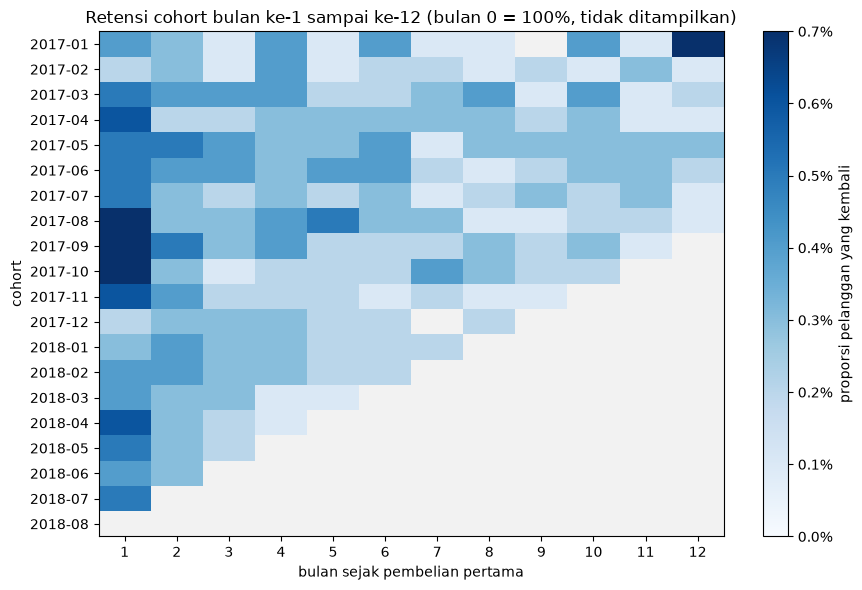

In [26]:
sub = ret.iloc[:, 1:13].to_numpy(dtype=float, copy=True)
sub[sub <= 0] = np.nan

cmap = plt.get_cmap("Blues").copy()
cmap.set_bad("#f2f2f2")

fig, ax = plt.subplots(figsize=(9, 6))
im = ax.imshow(sub, aspect="auto", cmap=cmap, vmin=0, vmax=np.nanmax(sub))
ax.set_xticks(range(sub.shape[1]))
ax.set_xticklabels(ret.columns[1:13])
ax.set_yticks(range(sub.shape[0]))
ax.set_yticklabels(ret.index)
ax.set_xlabel("bulan sejak pembelian pertama")
ax.set_ylabel("cohort")
ax.set_title("Retensi cohort bulan ke-1 sampai ke-12 (bulan 0 = 100%, tidak ditampilkan)")
fig.colorbar(im, ax=ax, label="proporsi pelanggan yang kembali", format=PercentFormatter(1.0, decimals=1))
plt.tight_layout()
plt.savefig(FIG / "cohort_retention.png", dpi=150)
plt.show()

## 8. Loyalitas

Pertanyaan kelima tidak bisa dijawab chart saja. Yang dibutuhkan adalah faktor apa yang membedakan pelanggan yang kembali dan yang tidak. Empat faktor diuji di sini, yaitu rating, keterlambatan kirim, kategori pertama, dan nilai belanja pertama.

Perbandingan pengiriman hanya memakai pelanggan yang order pertamanya sudah tiba. Order yang belum tiba tidak dihitung sebagai tepat waktu, karena tanggal tibanya belum ada.

Catatan batasan, dataset ini tidak punya data promo atau voucher, jadi efek kampanye tidak bisa diukur langsung.

In [27]:
con.execute("""
CREATE OR REPLACE TABLE marts.agg_loyalty AS
WITH rating AS (
    SELECT
        CASE
            WHEN coalesce(avg_review, 0) >= 4.5 THEN '4.5 - 5'
            WHEN avg_review >= 4.0 THEN '4.0 - 4.5'
            WHEN avg_review >= 3.0 THEN '3.0 - 4.0'
            ELSE '< 3.0'
        END AS bucket,
        count(*)                                                          AS customers,
        round(100.0 * avg(CASE WHEN n_orders >= 2 THEN 1 ELSE 0 END), 2)  AS repeat_rate_pct
    FROM marts.dim_customer
    GROUP BY 1
),
delivery AS (
    SELECT
        CASE WHEN first_late = 1 THEN 'terlambat' ELSE 'tepat waktu' END AS bucket,
        count(*)                                                          AS customers,
        round(100.0 * avg(CASE WHEN n_orders >= 2 THEN 1 ELSE 0 END), 2)  AS repeat_rate_pct
    FROM (
        SELECT
            customer_unique_id,
            count(*) AS n_orders,
            arg_min(late_flag, order_date) AS first_late
        FROM marts.fct_orders
        GROUP BY 1
    )
    WHERE first_late IS NOT NULL
    GROUP BY 1
),
kategori AS (
    SELECT
        first_category AS bucket,
        count(*)                                                          AS customers,
        round(100.0 * avg(CASE WHEN n_orders >= 2 THEN 1 ELSE 0 END), 2)  AS repeat_rate_pct
    FROM (
        SELECT
            customer_unique_id,
            count(*) AS n_orders,
            arg_min(category, order_date) AS first_category
        FROM marts.fct_orders
        GROUP BY 1
    )
    WHERE first_category IS NOT NULL
    GROUP BY 1
    HAVING count(*) >= 300
)
SELECT 'rating pertama'   AS factor, bucket, customers, repeat_rate_pct, 1 AS urutan FROM rating
UNION ALL
SELECT 'pengiriman pertama', bucket, customers, repeat_rate_pct, 2 FROM delivery
UNION ALL
SELECT 'kategori pertama',   bucket, customers, repeat_rate_pct, 3 FROM kategori
""")

q("SELECT * FROM marts.agg_loyalty ORDER BY urutan, repeat_rate_pct DESC")

,factor,bucket,customers,repeat_rate_pct,urutan
0,rating pertama,3.0 - 4.0,7994,5.69,1
1,rating pertama,4.5 - 5,54749,3.12,1
2,rating pertama,< 3.0,13687,2.41,1
3,rating pertama,4.0 - 4.5,18277,2.08,1
4,pengiriman pertama,tepat waktu,85500,3.13,2
5,pengiriman pertama,terlambat,7596,2.59,2
6,kategori pertama,home_appliances,687,8.88,3
7,kategori pertama,fashion_bags_accessories,1721,5.69,3
8,kategori pertama,furniture_living_room,398,5.03,3
9,kategori pertama,furniture_decor,5963,4.60,3


In [28]:
q("""
WITH o AS (
    SELECT
        customer_unique_id,
        order_date,
        row_number() OVER (PARTITION BY customer_unique_id ORDER BY order_date) AS rn,
        lag(order_date) OVER (PARTITION BY customer_unique_id ORDER BY order_date) AS prev_date
    FROM marts.fct_orders
)
SELECT
    count(*)                                                            AS pelanggan,
    round(median(date_diff('day', prev_date, order_date)), 1)           AS median_hari_ke_order_kedua,
    round(quantile_cont(date_diff('day', prev_date, order_date), 0.9), 1) AS p90_hari
FROM o
WHERE rn = 2
""")

,pelanggan,median_hari_ke_order_kedua,p90_hari
0,2875,28.0,246.0


## 9. Geografi

State sudah tersedia di `agg_state`. Untuk peta, geolocation tidak disimpan mentah. Satu juta baris diringkas jadi satu centroid per prefix kode pos, karena untuk peta level state cukup itu.

In [29]:
con.execute("""
CREATE OR REPLACE TABLE marts.dim_geo_prefix AS
SELECT
    geolocation_zip_code_prefix       AS zip_prefix,
    avg(geolocation_lat)              AS lat,
    avg(geolocation_lng)              AS lng,
    any_value(geolocation_state)      AS state
FROM raw_geolocation
GROUP BY 1
""")

q("SELECT count(*) AS prefix_pos, round(avg(lat), 3) AS lat_contoh FROM marts.dim_geo_prefix")

,prefix_pos,lat_contoh
0,19015,-19.055


In [30]:
q("""
SELECT
    customer_state AS state,
    count(DISTINCT customer_unique_id) AS customers,
    round(sum(payment_total) / count(DISTINCT customer_unique_id), 2) AS gmv_per_customer,
    round(avg(delivery_days), 1) AS rata_hari_kirim,
    round(100.0 * avg(late_flag), 1) AS late_rate_pct,
    round(avg(review_score), 2) AS rating
FROM marts.fct_orders
GROUP BY 1
HAVING count(DISTINCT customer_unique_id) >= 500
ORDER BY gmv_per_customer DESC
LIMIT 12
""")

,state,customers,gmv_per_customer,rata_hari_kirim,late_rate_pct,rating
0,PB,515,272.71,20.4,11.0,4.02
1,PA,940,230.00,23.7,12.4,3.85
2,MT,870,213.47,18.0,6.8,4.11
3,CE,1294,210.66,21.2,15.4,3.87
4,MA,711,210.54,21.5,19.6,3.78
5,PE,1593,200.52,18.4,10.8,4.02
6,MS,687,197.86,15.5,11.6,4.14
7,BA,3240,187.05,19.3,14.0,3.88
8,GO,1927,176.17,15.5,8.2,4.07
9,SC,3493,173.38,14.9,9.8,4.10


In [31]:
q("""
SELECT
    customer_state AS state,
    customer_city  AS city,
    count(*) AS orders,
    count(DISTINCT customer_unique_id) AS customers,
    round(sum(payment_total), 2) AS gmv
FROM marts.fct_orders
GROUP BY 1, 2
ORDER BY gmv DESC
LIMIT 10
""")

,state,city,orders,customers,gmv
0,SP,sao paulo,15257,14731,2146010.37
1,RJ,rio de janeiro,6772,6519,1140236.35
2,MG,belo horizonte,2726,2631,410022.30
3,DF,brasilia,2106,2046,349363.22
4,PR,curitiba,1496,1442,240162.67
5,RS,porto alegre,1364,1312,219130.45
6,BA,salvador,1234,1199,216352.82
7,SP,campinas,1416,1373,210947.88
8,SP,guarulhos,1166,1132,161643.29
9,RJ,niteroi,841,803,137085.73


## 10. Afinitas segmen dan kategori

Bahan untuk pertanyaan keenam. Matriks ini dipakai untuk memilih taktik per segmen, misalnya kategori apa yang layak dijadikan penawaran pada kampanye win-back.

In [32]:
con.execute("""
CREATE OR REPLACE TABLE marts.agg_segment_category AS
SELECT
    d.segment,
    f.category,
    count(*)                            AS orders,
    count(DISTINCT f.customer_unique_id) AS customers,
    sum(f.payment_total)                AS gmv
FROM marts.fct_orders f
JOIN marts.dim_customer d USING (customer_unique_id)
GROUP BY 1, 2
""")

q("""
SELECT segment, category, gmv
FROM (
    SELECT
        segment, category, gmv,
        row_number() OVER (PARTITION BY segment ORDER BY gmv DESC) AS rk
    FROM marts.agg_segment_category
    WHERE category IS NOT NULL
)
WHERE rk <= 3
ORDER BY segment, rk
""")

,segment,category,gmv
0,At Risk,bed_bath_table,72266.35
1,At Risk,sports_leisure,55764.17
2,At Risk,furniture_decor,47109.30
3,Champions,telephony,4943.58
4,Champions,bed_bath_table,4340.63
5,Champions,watches_gifts,3145.54
6,Dormant,bed_bath_table,592188.92
7,Dormant,sports_leisure,489383.76
8,Dormant,health_beauty,446567.22
9,Dormant High Value,watches_gifts,664846.08


Rekomendasi aksi per segmen. Tabel ini yang nanti dipindahkan ke halaman 4 dashboard dan ke laporan.

| Segmen | Tujuan | Taktik | KPI |
|---|---|---|---|
| Champions | pertahankan | akses awal produk baru, program referral | repeat rate, NPS |
| Loyal | naikkan nilai | bundling dan up-sell kategori favorit | AOV, item per order |
| Potential | dorong order kedua | voucher pembelian kedua berbatas waktu | konversi order kedua |
| New | bangun kebiasaan | email onboarding dan rekomendasi kategori | repeat 90 hari |
| At Risk | menangkan kembali | win-back dengan kategori yang pernah dibeli | reaktivasi |
| Hibernating | seleksi murah | kampanye email berbiaya rendah, tanpa diskon besar | biaya per reaktivasi |

## 11. Kontrak mart

Daftar tabel dan kolom yang boleh dibaca Streamlit. Kalau app butuh kolom baru, tambahkan di sini dulu, jangan join di app.

In [33]:
mart_tables = con.sql("""
SELECT table_name
FROM information_schema.tables
WHERE table_schema = 'marts'
ORDER BY 1
""").df()["table_name"].tolist()

contract = []
for t in mart_tables:
    cols = con.sql(f"DESCRIBE marts.{t}").df()["column_name"].tolist()
    contract.append({"tabel": t, "jumlah_kolom": len(cols), "kolom": ", ".join(cols)})

pd.DataFrame(contract)

,tabel,jumlah_kolom,kolom
0,agg_cohort,3,"cohort_month, month_index, customers"
1,agg_loyalty,5,"factor, bucket, customers, repeat_rate_pct, ur..."
2,agg_monthly,6,"order_month, orders, customers, gmv, aov, rating"
3,agg_segment,8,"segment, customers, gmv, avg_monetary, avg_ord..."
4,agg_segment_category,5,"segment, category, orders, customers, gmv"
5,agg_state,8,"state, orders, customers, gmv, gmv_per_custome..."
6,dim_customer,22,"customer_unique_id, first_order_date, last_ord..."
7,dim_geo_prefix,4,"zip_prefix, lat, lng, state"
8,fct_orders,20,"order_id, customer_unique_id, order_status, pu..."
9,int_customer_base,11,"customer_unique_id, first_order_date, last_ord..."


## 12. Rekonsiliasi

Tiga pemeriksaan wajib. Jumlah order di mart sama dengan jumlah order yang lolos filter. GMV di mart sama dengan penjumlahan payment mentah untuk order yang sama. Tidak ada pelanggan yatim setelah join.

In [34]:
q("""
SELECT
    (SELECT count(*) FROM marts.fct_orders) AS order_di_mart,
    (SELECT count(*) FROM raw_orders
      WHERE order_status NOT IN ('canceled', 'unavailable')
        AND CAST(order_purchase_timestamp AS TIMESTAMP) >= TIMESTAMP '2017-01-01'
        AND CAST(order_purchase_timestamp AS TIMESTAMP) <  TIMESTAMP '2018-09-01') AS order_di_raw,
    (SELECT round(sum(payment_total), 2) FROM marts.fct_orders) AS gmv_di_mart,
    (SELECT round(sum(p.payment_value), 2)
       FROM raw_payments p
       JOIN marts.fct_orders f ON f.order_id = p.order_id) AS gmv_di_raw
""")

,order_di_mart,order_di_raw,gmv_di_mart,gmv_di_raw
0,97910,97910,15687157.17,15687157.17


In [35]:
q("""
SELECT
    (SELECT count(*)
       FROM marts.fct_orders f
       LEFT JOIN marts.dim_customer d USING (customer_unique_id)
      WHERE d.customer_unique_id IS NULL) AS order_tanpa_customer,
    (SELECT count(*) FROM marts.dim_customer WHERE segment IS NULL) AS customer_tanpa_segmen,
    (SELECT count(*) FROM marts.dim_customer WHERE r_score IS NULL) AS skor_rfm_null
""")

,order_tanpa_customer,customer_tanpa_segmen,skor_rfm_null
0,0,0,0


## Catatan definisi metrik

Bagian ini untuk lampiran laporan. Semua definisi di bawah sudah dipakai konsisten di seluruh notebook dan nanti di dashboard.

| Metrik | Definisi | Sumber |
|---|---|---|
| GMV | jumlah `payment_total` pada order non-canceled | `marts.fct_orders` |
| AOV | GMV dibagi jumlah order | `marts.fct_orders` |
| Pelanggan | `count(DISTINCT customer_unique_id)` | `marts.fct_orders` |
| Repeat rate | pelanggan dengan minimal dua order dibagi total pelanggan | `marts.dim_customer` |
| Recency | selisih hari antara order terakhir dan tanggal acuan (order terakhir ditambah satu hari) | `marts.dim_customer` |
| RFM | R pita hari mengikuti ambang churn, F jumlah order dibatasi 5, M `ntile(5)` | `marts.dim_customer` |
| Churn risk | recency melebihi `greatest(2 x median gap, 90 hari)` | `marts.dim_customer` |
| Retensi cohort | pelanggan yang bertransaksi pada bulan ke-n dibagi ukuran cohort bulan pertama | `marts.agg_cohort` |

Langkah berikutnya, memindahkan query bagian 3 sampai 10 ke file `sql/`, lalu Streamlit hanya membaca schema `marts`.